In [1]:
import torch
import torch.nn.functional as F

from torch_geometric.nn import GCNConv

import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

C:\Users\nakul\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

Using device: cpu


In [3]:
GRAPH_PATH = "../data/processed/elliptic_graph.pt"

graph_data = torch.load(
    GRAPH_PATH,
    weights_only=False
)

print(graph_data)

Data(x=[203769, 165], edge_index=[2, 468710], y=[203769], train_mask=[203769], val_mask=[203769], test_mask=[203769])


In [4]:
print("Node features :", graph_data.x.shape)
print("Edges         :", graph_data.edge_index.shape)
print("Labels        :", graph_data.y.shape)

print("\nTrain nodes :", graph_data.train_mask.sum().item())
print("Valid nodes :", graph_data.val_mask.sum().item())
print("Test nodes  :", graph_data.test_mask.sum().item())

Node features : torch.Size([203769, 165])
Edges         : torch.Size([2, 468710])
Labels        : torch.Size([203769])

Train nodes : 29894
Valid nodes : 7829
Test nodes  : 8841


In [5]:
# Load graph_data ✅
#        ↓
# Define 2-layer GCN       ← NEXT
#        ↓
# Loss + optimizer
#        ↓
# Training loop
#        ↓
# Validation
#        ↓
# Test evaluation
#        ↓
# Save trained model
#        ↓
# GNNExplainer
#        ↓
# App

# Verify labels

In [6]:
print(
    "Unique labels:",
    torch.unique(graph_data.y)
)

Unique labels: tensor([-1,  0,  1])


In [7]:
unique_labels, counts = torch.unique(
    graph_data.y,
    return_counts=True
)

for label, count in zip(unique_labels, counts):
    print(
        f"Label {label.item()}: {count.item()} nodes"
    )

Label -1: 157205 nodes
Label 0: 42019 nodes
Label 1: 4545 nodes


In [8]:
train_labels = graph_data.y[
    graph_data.train_mask
]

unique_labels, counts = torch.unique(
    train_labels,
    return_counts=True
)

print("\nTraining label distribution:")

for label, count in zip(unique_labels, counts):
    print(
        f"Label {label.item()}: {count.item()}"
    )


Training label distribution:
Label 0: 26432
Label 1: 3462


In [9]:
graph_data = graph_data.to(device)

# Define our first GCN

In [10]:
class GCN(torch.nn.Module):

    def __init__(
        self,
        num_features,
        hidden_channels,
        num_classes
    ):

        super().__init__()

        self.conv1 = GCNConv(
            num_features,
            hidden_channels
        )

        self.conv2 = GCNConv(
            hidden_channels,
            num_classes
        )

    def forward(
        self,
        x,
        edge_index
    ):

        # First graph convolution
        x = self.conv1(
            x,
            edge_index
        )

        # Non-linearity
        x = F.relu(x)

        # Reduce overfitting
        x = F.dropout(
            x,
            p=0.5,
            training=self.training
        )

        # Final graph convolution
        x = self.conv2(
            x,
            edge_index
        )

        return x

# Create the model

In [11]:
num_features = graph_data.x.shape[1]

print("Number of input features:", num_features)

Number of input features: 165


In [12]:
num_classes = 2
hidden_channels = 64

In [13]:
model = GCN(
    num_features=num_features,
    hidden_channels=hidden_channels,
    num_classes=num_classes
).to(device)

print(model)

GCN(
  (conv1): GCNConv(165, 64)
  (conv2): GCNConv(64, 2)
)


In [14]:
# What is actually happening here?
# This part:
# self.conv1 = GCNConv(    num_features,    64)


# means every transaction starts with something like:
# Transaction A
# [feature1, feature2, ... feature165]

# GCN doesn't examine Transaction A alone.
# It aggregates information from its graph neighborhood:
#              Transaction B
#                     ↓
# Transaction C → Transaction A ← Transaction D
#                     ↑
#              Transaction E

# Conceptually:
# A's own features
#         +
# features from neighboring transactions
#         ↓
#         GCN
#         ↓
# new representation of A

# So after the first layer:
# 165 original features
#         ↓
# 64 learned graph-aware features

# Those 64 values are no longer ordinary dataset columns. They're embeddings learned by the network.
# Then:
# self.conv2 = GCNConv(    64,    2)


# converts that learned representation into two scores:
# [score_class_0, score_class_1]

# For example:
# [-1.2, 2.8]

# would indicate the second class is preferred.

In [15]:
print(torch.unique(graph_data.y))

tensor([-1,  0,  1])


In [16]:
unique_labels, counts = torch.unique(
    graph_data.y[graph_data.train_mask],
    return_counts=True
)

for label, count in zip(unique_labels, counts):
    print(label.item(), count.item())

0 26432
1 3462


In [17]:
train_labels = graph_data.y[
    graph_data.train_mask
]

class_counts = torch.bincount(train_labels)

print("Class counts:", class_counts)

Class counts: tensor([26432,  3462])


In [18]:
CLASS_WEIGHTS_PATH = "../data/processed/class_weights.pt"

class_weights = torch.load(
    CLASS_WEIGHTS_PATH,
    weights_only=True
).to(device)

print("Loaded class weights:", class_weights)

Loaded class weights: tensor([0.5655, 4.3174])


In [19]:
criterion = torch.nn.CrossEntropyLoss(
    weight=class_weights
)

In [20]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.01,
    weight_decay=5e-4
)

# training function:

In [21]:
def train():
    model.train()

    optimizer.zero_grad()

    out = model(
        graph_data.x,
        graph_data.edge_index
    )

    loss = criterion(
        out[graph_data.train_mask],
        graph_data.y[graph_data.train_mask]
    )

    loss.backward()

    optimizer.step()

    return loss.item()

# add a prediction helper:

In [22]:
@torch.no_grad()
def predict(mask):

    model.eval()

    out = model(
        graph_data.x,
        graph_data.edge_index
    )

    predictions = out.argmax(dim=1)

    y_true = graph_data.y[mask]
    y_pred = predictions[mask]

    return y_true, y_pred

In [23]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def evaluate(mask):
    y_true, y_pred = predict(mask)

    y_true = y_true.cpu().numpy()
    y_pred = y_pred.cpu().numpy()

    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        "recall": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        "f1": f1_score(y_true, y_pred, pos_label=1, zero_division=0)
    }

In [24]:
num_epochs = 100

train_losses = []
val_f1_scores = []

best_val_f1 = 0.0

for epoch in range(1, num_epochs + 1):

    loss = train()

    val_metrics = evaluate(
        graph_data.val_mask
    )

    train_losses.append(loss)
    val_f1_scores.append(
        val_metrics["f1"]
    )

    # Save model only when validation F1 improves
    if val_metrics["f1"] > best_val_f1:

        best_val_f1 = val_metrics["f1"]

        torch.save(
            model.state_dict(),
            "best_gcn_model.pt"
        )

    if epoch % 10 == 0 or epoch == 1:

        print(
            f"Epoch {epoch:03d} | "
            f"Loss: {loss:.4f} | "
            f"Val Acc: {val_metrics['accuracy']:.4f} | "
            f"Val Precision: {val_metrics['precision']:.4f} | "
            f"Val Recall: {val_metrics['recall']:.4f} | "
            f"Val F1: {val_metrics['f1']:.4f}"
        )

print(
    "\nBest Validation F1:",
    best_val_f1
)

Epoch 001 | Loss: 0.7311 | Val Acc: 0.6259 | Val Precision: 0.1712 | Val Recall: 0.8696 | Val F1: 0.2861
Epoch 010 | Loss: 0.2961 | Val Acc: 0.7818 | Val Precision: 0.2374 | Val Recall: 0.6919 | Val F1: 0.3535
Epoch 020 | Loss: 0.2400 | Val Acc: 0.8476 | Val Precision: 0.3259 | Val Recall: 0.7185 | Val F1: 0.4485
Epoch 030 | Loss: 0.2122 | Val Acc: 0.8594 | Val Precision: 0.3483 | Val Recall: 0.7244 | Val F1: 0.4704
Epoch 040 | Loss: 0.1955 | Val Acc: 0.8686 | Val Precision: 0.3665 | Val Recall: 0.7200 | Val F1: 0.4858
Epoch 050 | Loss: 0.1813 | Val Acc: 0.8829 | Val Precision: 0.3990 | Val Recall: 0.7081 | Val F1: 0.5104
Epoch 060 | Loss: 0.1707 | Val Acc: 0.8907 | Val Precision: 0.4210 | Val Recall: 0.7141 | Val F1: 0.5297
Epoch 070 | Loss: 0.1567 | Val Acc: 0.8923 | Val Precision: 0.4273 | Val Recall: 0.7319 | Val F1: 0.5396
Epoch 080 | Loss: 0.1521 | Val Acc: 0.9038 | Val Precision: 0.4633 | Val Recall: 0.7289 | Val F1: 0.5665
Epoch 090 | Loss: 0.1453 | Val Acc: 0.9062 | Val Precis

In [25]:
model.load_state_dict(
    torch.load(
        "best_gcn_model.pt",
        map_location=device
    )
)

model.eval()

GCN(
  (conv1): GCNConv(165, 64)
  (conv2): GCNConv(64, 2)
)

In [26]:
test_metrics = evaluate(graph_data.test_mask)

print("\nTest Results")
print("Accuracy :", test_metrics["accuracy"])
print("Precision:", test_metrics["precision"])
print("Recall   :", test_metrics["recall"])
print("F1 Score :", test_metrics["f1"])


Test Results
Accuracy : 0.9554349055536704
Precision: 0.5220125786163522
Recall   : 0.4068627450980392
F1 Score : 0.4573002754820937


# add a full classification report:

In [27]:
from sklearn.metrics import classification_report

y_true, y_pred = predict(graph_data.test_mask)

print(
    classification_report(
        y_true.cpu().numpy(),
        y_pred.cpu().numpy(),
        target_names=["Legitimate", "Fraud"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

  Legitimate       0.97      0.98      0.98      8433
       Fraud       0.52      0.41      0.46       408

    accuracy                           0.96      8841
   macro avg       0.75      0.69      0.72      8841
weighted avg       0.95      0.96      0.95      8841



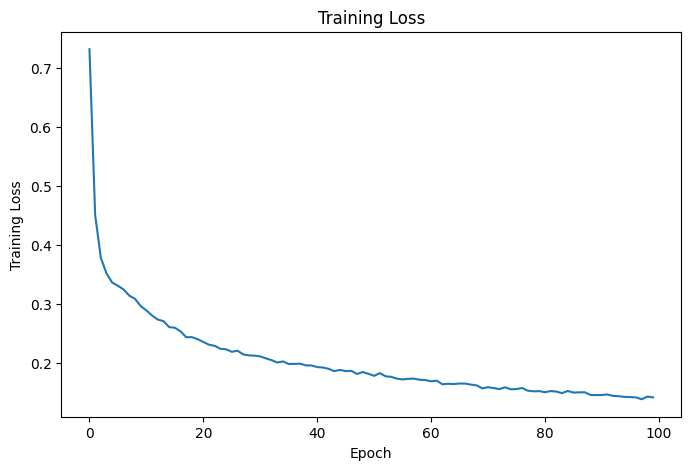

In [28]:
plt.figure(figsize=(8, 5))
plt.plot(train_losses)
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Training Loss")
plt.show()

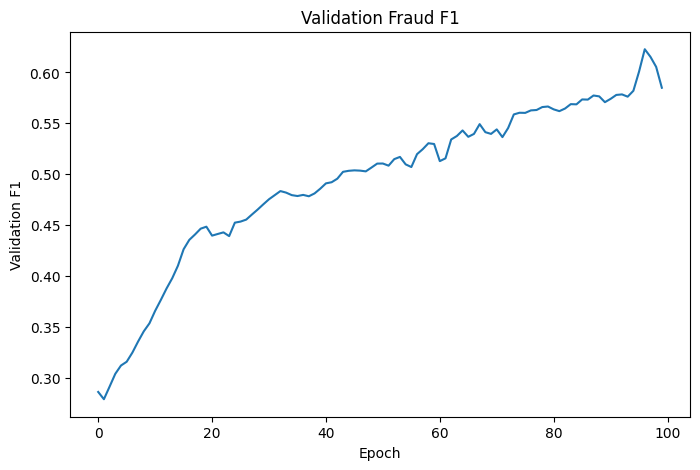

In [29]:
plt.figure(figsize=(8, 5))
plt.plot(val_f1_scores)
plt.xlabel("Epoch")
plt.ylabel("Validation F1")
plt.title("Validation Fraud F1")
plt.show()

# Confusion Matrix

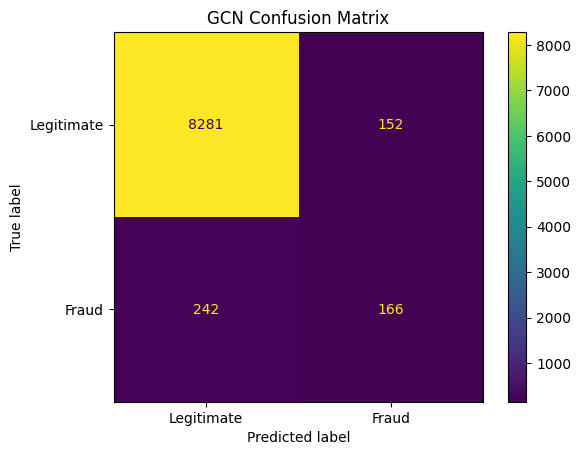

In [30]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_true, y_pred = predict(graph_data.test_mask)

cm = confusion_matrix(
    y_true.cpu().numpy(),
    y_pred.cpu().numpy()
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Legitimate", "Fraud"]
)

disp.plot()
plt.title("GCN Confusion Matrix")
plt.show()

# GNNExplainer.

In [31]:
model.load_state_dict(
    torch.load(
        "best_gcn_model.pt",
        map_location=device
    )
)

model.eval()

GCN(
  (conv1): GCNConv(165, 64)
  (conv2): GCNConv(64, 2)
)

In [32]:
with torch.no_grad():
    out = model(
        graph_data.x,
        graph_data.edge_index
    )

    predictions = out.argmax(dim=1)

In [33]:
correct_fraud_nodes = torch.where(
    (graph_data.test_mask) &
    (graph_data.y == 1) &
    (predictions == 1)
)[0]

print(
    "Correctly predicted fraud nodes:",
    len(correct_fraud_nodes)
)

print(
    "First few:",
    correct_fraud_nodes[:10]
)

Correctly predicted fraud nodes: 166
First few: tensor([166967, 167101, 167221, 167298, 167322, 167404, 167519, 167533, 167640,
        167693])


In [34]:
node_idx = correct_fraud_nodes[0].item()

print("Selected node:", node_idx)
print("True label:", graph_data.y[node_idx].item())
print("Predicted label:", predictions[node_idx].item())

Selected node: 166967
True label: 1
Predicted label: 1


In [35]:
from torch_geometric.explain import Explainer, GNNExplainer

In [36]:
explainer = Explainer(
    model=model,

    algorithm=GNNExplainer(
        epochs=100
    ),

    explanation_type="model",

    node_mask_type="attributes",

    edge_mask_type="object",

    model_config=dict(
        mode="multiclass_classification",
        task_level="node",
        return_type="raw"
    )
)

In [37]:
explanation = explainer(
    graph_data.x,
    graph_data.edge_index,
    index=node_idx
)

In [38]:
print(explanation)

Explanation(node_mask=[203769, 165], edge_mask=[468710], prediction=[203769, 2], target=[203769], index=[1], x=[203769, 165], edge_index=[2, 468710])


In [39]:
print(
    "Node mask shape:",
    explanation.node_mask.shape
)

print(
    "Edge mask shape:",
    explanation.edge_mask.shape
)

Node mask shape: torch.Size([203769, 165])
Edge mask shape: torch.Size([468710])


In [40]:
# Conceptually, GNNExplainer is learning two things:
# Which node features mattered?
#         +
# Which graph connections mattered?

# So if the model sees something like:
# Transaction A
#    ↑       ↑
#    │       │
# Transaction B   Transaction C

# GNNExplainer may discover that the edge:
# B → A
# was much more influential than:
# C → A

In [41]:
print(explanation)
print(explanation.node_mask.shape)
print(explanation.edge_mask.shape)

Explanation(node_mask=[203769, 165], edge_mask=[468710], prediction=[203769, 2], target=[203769], index=[1], x=[203769, 165], edge_index=[2, 468710])
torch.Size([203769, 165])
torch.Size([468710])


## Top features for the selected fraud node

In [42]:
feature_importance = explanation.node_mask[node_idx]

top_k = 10

top_values, top_indices = torch.topk(
    feature_importance,
    k=top_k
)

print("Top important features:\n")

for rank, (feature_idx, importance) in enumerate(
    zip(top_indices, top_values),
    start=1
):
    print(
        f"{rank}. Feature {feature_idx.item()} "
        f"-> Importance: {importance.item():.4f}"
    )

Top important features:

1. Feature 113 -> Importance: 0.7180
2. Feature 151 -> Importance: 0.7151
3. Feature 114 -> Importance: 0.6971
4. Feature 139 -> Importance: 0.6947
5. Feature 1 -> Importance: 0.6939
6. Feature 111 -> Importance: 0.6908
7. Feature 90 -> Importance: 0.6867
8. Feature 7 -> Importance: 0.6854
9. Feature 77 -> Importance: 0.6835
10. Feature 8 -> Importance: 0.6830


In [43]:
## Find the most important graph connections

In [44]:
edge_importance = explanation.edge_mask

top_k_edges = 10

top_edge_values, top_edge_indices = torch.topk(
    edge_importance,
    k=top_k_edges
)

print("Top important edges:\n")

for rank, (edge_idx, importance) in enumerate(
    zip(top_edge_indices, top_edge_values),
    start=1
):

    source = graph_data.edge_index[0, edge_idx].item()
    target = graph_data.edge_index[1, edge_idx].item()

    print(
        f"{rank}. {source} -> {target} "
        f"| Importance: {importance.item():.4f}"
    )

Top important edges:

1. 173026 -> 167299 | Importance: 0.7868
2. 167298 -> 167299 | Importance: 0.7848
3. 172621 -> 167299 | Importance: 0.7843
4. 166967 -> 173663 | Importance: 0.7287
5. 173663 -> 166967 | Importance: 0.6991
6. 167299 -> 166967 | Importance: 0.6834
7. 166966 -> 166967 | Importance: 0.5733
8. 170432 -> 166966 | Importance: 0.3102
9. 167567 -> 166966 | Importance: 0.2932
10. 172658 -> 167299 | Importance: 0.2297


In [45]:
source_nodes = graph_data.edge_index[0]
target_nodes = graph_data.edge_index[1]

connected_mask = (
    (source_nodes == node_idx) |
    (target_nodes == node_idx)
)

connected_edge_indices = torch.where(
    connected_mask
)[0]

print(
    "Directly connected edges:",
    len(connected_edge_indices)
)

Directly connected edges: 6


## rank those edges by GNNExplainer importance:

In [46]:
connected_importance = edge_importance[
    connected_edge_indices
]

k = min(
    10,
    len(connected_edge_indices)
)

values, positions = torch.topk(
    connected_importance,
    k=k
)

print("\nMost influential direct connections:\n")

for rank, (position, importance) in enumerate(
    zip(positions, values),
    start=1
):

    edge_idx = connected_edge_indices[position]

    source = graph_data.edge_index[
        0, edge_idx
    ].item()

    target = graph_data.edge_index[
        1, edge_idx
    ].item()

    neighbor = (
        target
        if source == node_idx
        else source
    )

    print(
        f"{rank}. Neighbor node {neighbor} "
        f"| Edge importance: {importance.item():.4f}"
    )


Most influential direct connections:

1. Neighbor node 173663 | Edge importance: 0.7287
2. Neighbor node 173663 | Edge importance: 0.6991
3. Neighbor node 167299 | Edge importance: 0.6834
4. Neighbor node 166966 | Edge importance: 0.5733
5. Neighbor node 166966 | Edge importance: 0.2207
6. Neighbor node 167299 | Edge importance: 0.2197


In [47]:
# This second output is much more useful for our project because now we can say something like:
# Transaction X was predicted as fraudulent partly because of its relationship with transactions A, B, and C.

# And together with the feature explanation:
#                   FRAUD PREDICTION
#                          │
#           ┌──────────────┴──────────────┐
#           │                             │
#      Feature-level                 Graph-level
#      explanation                   explanation
#           │                             │
#    Feature 53: 0.81             Neighbor 7241: 0.92
#    Feature 12: 0.76             Neighbor 8192: 0.73
#    Feature 91: 0.70             Neighbor 4421: 0.61

# That's already the core of the explainable fraud detection part of V1.

In [48]:
print("Selected node:", node_idx)
print("Number of direct connections:", connected_mask.sum().item())

print(
    "Non-zero explanation edges:",
    (explanation.edge_mask > 0).sum().item()
)

Selected node: 166967
Number of direct connections: 6
Non-zero explanation edges: 32


## The next step is to make the explanation more 
## interpretable by deduplicating direct neighbors and aggregating their edge importance.

In [49]:
from collections import defaultdict

neighbor_importance = defaultdict(float)

for edge_idx in connected_edge_indices:

    source = graph_data.edge_index[0, edge_idx].item()
    target = graph_data.edge_index[1, edge_idx].item()

    importance = explanation.edge_mask[edge_idx].item()

    if source == node_idx:
        neighbor = target
    else:
        neighbor = source

    neighbor_importance[neighbor] += importance

In [50]:
sorted_neighbors = sorted(
    neighbor_importance.items(),
    key=lambda x: x[1],
    reverse=True
)

print("Most influential neighboring transactions:\n")

for rank, (neighbor, importance) in enumerate(
    sorted_neighbors[:10],
    start=1
):
    print(
        f"{rank}. Neighbor {neighbor} "
        f"| Combined importance: {importance:.4f}"
    )

Most influential neighboring transactions:

1. Neighbor 173663 | Combined importance: 1.4278
2. Neighbor 167299 | Combined importance: 0.9031
3. Neighbor 166966 | Combined importance: 0.7941


In [51]:
print("Selected node:", node_idx)
print("Selected node label:", graph_data.y[node_idx].item())

print("\nNeighbor information:\n")

for neighbor, importance in sorted_neighbors[:10]:

    label = graph_data.y[neighbor].item()

    if label == 1:
        label_name = "Fraud"
    elif label == 0:
        label_name = "Legitimate"
    else:
        label_name = "Unknown"

    print(
        f"Neighbor {neighbor} "
        f"| Label: {label_name} "
        f"| Importance: {importance:.4f}"
    )

Selected node: 166967
Selected node label: 1

Neighbor information:

Neighbor 173663 | Label: Unknown | Importance: 1.4278
Neighbor 167299 | Label: Unknown | Importance: 0.9031
Neighbor 166966 | Label: Unknown | Importance: 0.7941


## create a small local explanation graph centered on transaction 166967

In [52]:
import networkx as nx
import matplotlib.pyplot as plt

In [53]:
G = nx.Graph()

selected_node = node_idx

G.add_node(
    selected_node,
    label="Fraud"
)

top_neighbors = sorted_neighbors[:5]

for neighbor, importance in top_neighbors:

    neighbor_label = graph_data.y[neighbor].item()

    if neighbor_label == 1:
        label_name = "Fraud"
    elif neighbor_label == 0:
        label_name = "Legitimate"
    else:
        label_name = "Unknown"

    G.add_node(
        neighbor,
        label=label_name
    )

    G.add_edge(
        selected_node,
        neighbor,
        weight=importance
    )

# Top Feature Bar

In [54]:
# Extract top feature importances

In [55]:
top_k = 10

feature_importance = explanation.node_mask[node_idx]

top_values, top_indices = torch.topk(
    feature_importance,
    k=top_k
)

top_values = top_values.detach().cpu().numpy()
top_indices = top_indices.detach().cpu().numpy()

print("Top important features:\n")
for rank, (feature_idx, importance) in enumerate(
    zip(top_indices, top_values),
    start=1
):
    print(
        f"{rank}. Feature {feature_idx} "
        f"| Importance: {importance:.4f}"
    )

Top important features:

1. Feature 113 | Importance: 0.7180
2. Feature 151 | Importance: 0.7151
3. Feature 114 | Importance: 0.6971
4. Feature 139 | Importance: 0.6947
5. Feature 1 | Importance: 0.6939
6. Feature 111 | Importance: 0.6908
7. Feature 90 | Importance: 0.6867
8. Feature 7 | Importance: 0.6854
9. Feature 77 | Importance: 0.6835
10. Feature 8 | Importance: 0.6830


In [56]:
# Plot top-feature bar chart

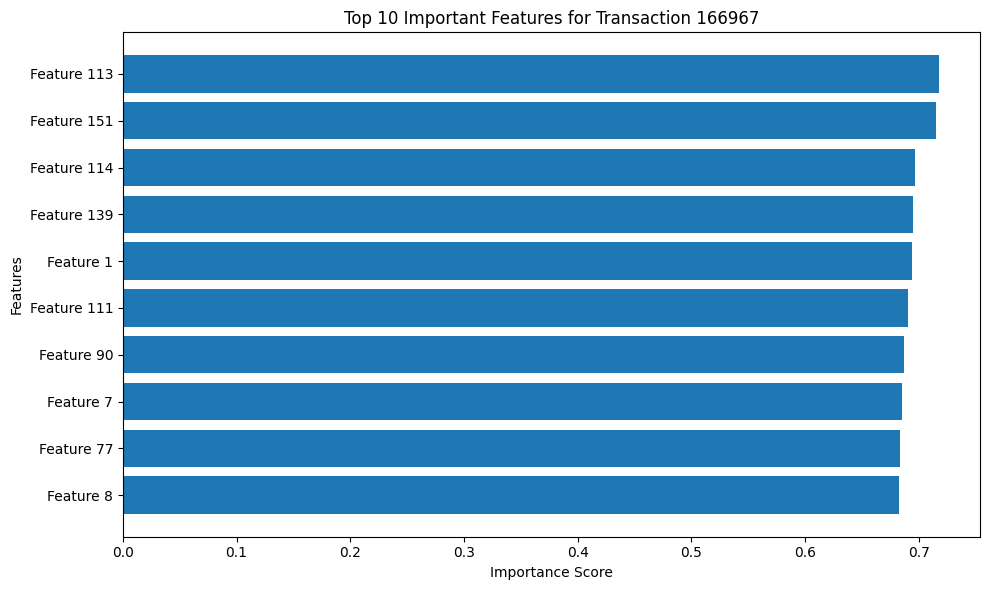

In [57]:
import matplotlib.pyplot as plt

feature_labels = [
    f"Feature {idx}"
    for idx in top_indices
]

plt.figure(figsize=(10, 6))
plt.barh(feature_labels, top_values)
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.title(f"Top {top_k} Important Features for Transaction {node_idx}")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# Validation and Stabilization of GNN Explainer

In [58]:
explanation = explainer(
    graph_data.x,
    graph_data.edge_index,
    index=node_idx
)

In [59]:

# GNNExplainer implementation audit
# Read-only diagnostic: does not retrain the GCN.

print("Selected node:", node_idx)
print("True label:", graph_data.y[node_idx].item())

model.eval()
with torch.no_grad():
    logits = model(graph_data.x, graph_data.edge_index)
    original_prediction = logits[node_idx].argmax().item()
    probabilities = torch.softmax(logits[node_idx], dim=0)

print("Original model prediction:", original_prediction)
print("Class probabilities:", probabilities.cpu().tolist())

print("\nExplanation output:")
print(explanation)

print("\nNode mask:")
if explanation.node_mask is None:
    print("No node/feature mask returned.")
else:
    print("Shape:", tuple(explanation.node_mask.shape))
    print("Minimum:", explanation.node_mask.min().item())
    print("Maximum:", explanation.node_mask.max().item())
    print("First values:", explanation.node_mask.flatten()[:10].tolist())

print("\nEdge mask:")
if explanation.edge_mask is None:
    print("No edge mask returned.")
else:
    print("Shape:", tuple(explanation.edge_mask.shape))
    print("Minimum:", explanation.edge_mask.min().item())
    print("Maximum:", explanation.edge_mask.max().item())
    print("First values:", explanation.edge_mask[:10].tolist())

print("\nExplanation prediction target:", explanation.target)
print("Prediction agrees with selected node:", original_prediction == predictions[node_idx].item())


Selected node: 166967
True label: 1
Original model prediction: 1
Class probabilities: [0.031196072697639465, 0.9688039422035217]

Explanation output:
Explanation(node_mask=[203769, 165], edge_mask=[468710], prediction=[203769, 2], target=[203769], index=[1], x=[203769, 165], edge_index=[2, 468710])

Node mask:
Shape: (203769, 165)
Minimum: 0.0
Maximum: 0.717510461807251
First values: [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]

Edge mask:
Shape: (468710,)
Minimum: 0.0
Maximum: 0.7814933061599731
First values: [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]

Explanation prediction target: tensor([0, 0, 0,  ..., 0, 0, 0])
Prediction agrees with selected node: True


In [60]:
print("Requested node_idx:", node_idx)
print("Stored explanation index:", explanation.index)

print("\nSelected node's explanation target:",
      explanation.target[node_idx].item())

print("Selected node's stored prediction:",
      explanation.prediction[node_idx].argmax().item())

print("\nFeature mask for selected node:")
print("Shape:", tuple(explanation.node_mask[node_idx].shape))
print("Top 10 feature-mask values:",
      torch.topk(explanation.node_mask[node_idx], k=10).values.tolist())

print("\nTop 10 edge-mask values:")
print(torch.topk(explanation.edge_mask, k=10).values.tolist())


Requested node_idx: 166967
Stored explanation index: tensor([166967])

Selected node's explanation target: 1
Selected node's stored prediction: 1

Feature mask for selected node:
Shape: (165,)
Top 10 feature-mask values: [0.7073383331298828, 0.6977329850196838, 0.6969555020332336, 0.6945138573646545, 0.6902201175689697, 0.6872674822807312, 0.6846555471420288, 0.6845227479934692, 0.683264434337616, 0.6829090714454651]

Top 10 edge-mask values:
[0.7814933061599731, 0.7308717370033264, 0.7004183530807495, 0.6786731481552124, 0.6504327654838562, 0.30930858850479126, 0.27397364377975464, 0.25220492482185364, 0.236191064119339, 0.23431043326854706]


In [61]:
# Inspect the top 10 features for the selected transaction

feature_importance = explanation.node_mask[node_idx]

top_k = 10
top_values, top_indices = torch.topk(
    feature_importance,
    k=top_k
)

print(f"Top {top_k} features for node {node_idx}:")

for rank, (feature_idx, importance) in enumerate(
    zip(top_indices.tolist(), top_values.tolist()),
    start=1
):
    print(
        f"{rank:2}. Feature index: {feature_idx:3} | "
        f"Importance: {importance:.4f}"
    )

Top 10 features for node 166967:
 1. Feature index: 155 | Importance: 0.7073
 2. Feature index:  99 | Importance: 0.6977
 3. Feature index:  20 | Importance: 0.6970
 4. Feature index: 113 | Importance: 0.6945
 5. Feature index:  81 | Importance: 0.6902
 6. Feature index: 156 | Importance: 0.6873
 7. Feature index: 142 | Importance: 0.6847
 8. Feature index:  17 | Importance: 0.6845
 9. Feature index: 107 | Importance: 0.6833
10. Feature index: 139 | Importance: 0.6829


In [63]:
# List notebook variables that may contain the raw dataset
for name, value in globals().copy().items():
    if (
        "DataFrame" in str(type(value))
        or "features" in name.lower()
        or "elliptic" in name.lower()
    ):
        print(
            f"{name}: type={type(value).__name__}, "
            f"shape={getattr(value, 'shape', 'N/A')}"
        )

num_features: type=int, shape=N/A


In [65]:
import pandas as pd

# The raw Elliptic features CSV has no header row.
# Its columns are: txId, time_step, and 165 features.
feature_columns = (
    ["txId", "time_step"]
    + [f"feature_{i}" for i in range(165)]
)

print("Total columns:", len(feature_columns))
print("First 5:", feature_columns[:5])
print("Last 5:", feature_columns[-5:])

# Map the top feature indices to names
for rank, (feature_idx, importance) in enumerate(
    zip(top_indices.tolist(), top_values.tolist()),
    start=1
):
    print(
        f"{rank:2}. feature_{feature_idx} "
        f"(importance={importance:.4f})"
    )

Total columns: 167
First 5: ['txId', 'time_step', 'feature_0', 'feature_1', 'feature_2']
Last 5: ['feature_160', 'feature_161', 'feature_162', 'feature_163', 'feature_164']
 1. feature_155 (importance=0.7073)
 2. feature_99 (importance=0.6977)
 3. feature_20 (importance=0.6970)
 4. feature_113 (importance=0.6945)
 5. feature_81 (importance=0.6902)
 6. feature_156 (importance=0.6873)
 7. feature_142 (importance=0.6847)
 8. feature_17 (importance=0.6845)
 9. feature_107 (importance=0.6833)
10. feature_139 (importance=0.6829)


In [68]:
# Rank only edges directly connected to the selected transaction

source_nodes = graph_data.edge_index[0]
target_nodes = graph_data.edge_index[1]

connected_mask = (
    (source_nodes == node_idx) |
    (target_nodes == node_idx)
)

connected_edge_indices = torch.where(connected_mask)[0]

connected_importance = explanation.edge_mask[connected_edge_indices]

top_k_edges = min(10, connected_edge_indices.numel())

top_values, top_positions = torch.topk(
    connected_importance,
    k=top_k_edges
)

top_edge_indices = connected_edge_indices[top_positions]

print(f"Top {top_k_edges} edges directly connected to node {node_idx}:\n")

for rank, (edge_idx, importance) in enumerate(
    zip(top_edge_indices.tolist(), top_values.tolist()),
    start=1
):
    source = source_nodes[edge_idx].item()
    target = target_nodes[edge_idx].item()

    print(
        f"{rank:2}. Edge {source} -> {target} | "
        f"Importance: {importance:.4f}"
    )

Top 6 edges directly connected to node 166967:

 1. Edge 166967 -> 173663 | Importance: 0.7309
 2. Edge 173663 -> 166967 | Importance: 0.7004
 3. Edge 167299 -> 166967 | Importance: 0.6787
 4. Edge 166966 -> 166967 | Importance: 0.6504
 5. Edge 166967 -> 166966 | Importance: 0.2206
 6. Edge 166967 -> 167299 | Importance: 0.2195


In [76]:
from torch_geometric.explain import Explainer, GNNExplainer

explainer_common = Explainer(
    model=model,
    algorithm=GNNExplainer(epochs=100),
    explanation_type="model",
    node_mask_type="common_attributes",
    edge_mask_type="object",
    model_config=dict(
        mode="multiclass_classification",
        task_level="node",
        return_type="raw"
    )
)

explanation_common = explainer_common(
    graph_data.x,
    graph_data.edge_index,
    index=node_idx
)

print("Selected node:", node_idx)
print("Original explanation mask:", tuple(explanation.node_mask.shape))
print("Common-attributes mask:", tuple(explanation_common.node_mask.shape))
print("Edge mask:", tuple(explanation_common.edge_mask.shape))
print("Explanation target:", explanation_common.target[node_idx].item())

Selected node: 166967
Original explanation mask: (203769, 165)
Common-attributes mask: (1, 165)
Edge mask: (468710,)
Explanation target: 1


In [77]:
# Rank features using the shared-attributes explanation

common_feature_importance = explanation_common.node_mask.squeeze(0)

top_k = 10
common_values, common_indices = torch.topk(
    common_feature_importance,
    k=top_k
)

print(f"Top {top_k} shared features for node {node_idx}:\n")

for rank, (feature_idx, importance) in enumerate(
    zip(common_indices.tolist(), common_values.tolist()),
    start=1
):
    print(
        f"{rank:2}. feature_{feature_idx:03d} | "
        f"Mask score: {importance:.4f}"
    )

Top 10 shared features for node 166967:

 1. feature_147 | Mask score: 0.6956
 2. feature_149 | Mask score: 0.6945
 3. feature_111 | Mask score: 0.6822
 4. feature_114 | Mask score: 0.6806
 5. feature_051 | Mask score: 0.6796
 6. feature_001 | Mask score: 0.6731
 7. feature_142 | Mask score: 0.6695
 8. feature_080 | Mask score: 0.6692
 9. feature_006 | Mask score: 0.6661
10. feature_054 | Mask score: 0.6605


In [79]:
original_top10 = set(top_indices.tolist())
common_top10 = set(common_indices.tolist())

print("Original top 10:", sorted(original_top10))
print("Shared-mask top 10:", sorted(common_top10))
print("Features appearing in both:", sorted(original_top10 & common_top10))
print(
    "Top-10 overlap:",
    len(original_top10 & common_top10),
    "/ 10"
)

Original top 10: [17, 20, 81, 99, 107, 113, 139, 142, 155, 156]
Shared-mask top 10: [1, 6, 51, 54, 80, 111, 114, 142, 147, 149]
Features appearing in both: [142]
Top-10 overlap: 1 / 10


In [81]:
# Repeat the original explanation with a fresh explainer instance.
# This does not retrain or modify the GCN.

explainer_repeat = Explainer(
    model=model,
    algorithm=GNNExplainer(epochs=100),
    explanation_type="model",
    node_mask_type="attributes",
    edge_mask_type="object",
    model_config=dict(
        mode="multiclass_classification",
        task_level="node",
        return_type="raw"
    )
)

explanation_repeat = explainer_repeat(
    graph_data.x,
    graph_data.edge_index,
    index=node_idx
)

repeat_importance = explanation_repeat.node_mask[node_idx]

repeat_values, repeat_indices = torch.topk(
    repeat_importance,
    k=10
)

print("Repeated run — top 10 features:")
for rank, (feature_idx, importance) in enumerate(
    zip(repeat_indices.tolist(), repeat_values.tolist()),
    start=1
):
    print(
        f"{rank:2}. feature_{feature_idx:03d} | "
        f"Mask score: {importance:.4f}"
    )

repeat_top10 = set(repeat_indices.tolist())
print("\nOverlap with first original run:",
      len(original_top10 & repeat_top10), "/ 10")
print("Shared features:", sorted(original_top10 & repeat_top10))

Repeated run — top 10 features:
 1. feature_159 | Mask score: 0.7082
 2. feature_113 | Mask score: 0.7072
 3. feature_135 | Mask score: 0.6994
 4. feature_001 | Mask score: 0.6971
 5. feature_151 | Mask score: 0.6939
 6. feature_111 | Mask score: 0.6930
 7. feature_099 | Mask score: 0.6913
 8. feature_054 | Mask score: 0.6902
 9. feature_158 | Mask score: 0.6834
10. feature_157 | Mask score: 0.6794

Overlap with first original run: 2 / 10
Shared features: [99, 113]


In [82]:
import random
import numpy as np
import torch

seed = 42

random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

explainer_seeded = Explainer(
    model=model,
    algorithm=GNNExplainer(epochs=100),
    explanation_type="model",
    node_mask_type="attributes",
    edge_mask_type="object",
    model_config=dict(
        mode="multiclass_classification",
        task_level="node",
        return_type="raw"
    )
)

explanation_seeded = explainer_seeded(
    graph_data.x,
    graph_data.edge_index,
    index=node_idx
)

seeded_importance = explanation_seeded.node_mask[node_idx]
seeded_values, seeded_indices = torch.topk(seeded_importance, k=10)

seeded_top10 = set(seeded_indices.tolist())

print("Seeded run — top 10 features:")
for rank, (feature_idx, importance) in enumerate(
    zip(seeded_indices.tolist(), seeded_values.tolist()),
    start=1
):
    print(
        f"{rank:2}. feature_{feature_idx:03d} | "
        f"Mask score: {importance:.4f}"
    )

print("\nOverlap with first original run:",
      len(original_top10 & seeded_top10), "/ 10")
print("Shared features:", sorted(original_top10 & seeded_top10))

Seeded run — top 10 features:
 1. feature_113 | Mask score: 0.7385
 2. feature_151 | Mask score: 0.7246
 3. feature_099 | Mask score: 0.7037
 4. feature_135 | Mask score: 0.6972
 5. feature_114 | Mask score: 0.6906
 6. feature_139 | Mask score: 0.6807
 7. feature_147 | Mask score: 0.6781
 8. feature_162 | Mask score: 0.6755
 9. feature_090 | Mask score: 0.6738
10. feature_107 | Mask score: 0.6719

Overlap with first original run: 4 / 10
Shared features: [99, 107, 113, 139]


In [83]:
# Sensitivity test: zero the top-ranked input features for the selected node.
# This does not retrain or modify the model or graph.

model.eval()

feature_ids = seeded_indices.tolist()
x_modified = graph_data.x.clone()
x_modified[node_idx, feature_ids] = 0.0

with torch.no_grad():
    original_logits = model(graph_data.x, graph_data.edge_index)
    modified_logits = model(x_modified, graph_data.edge_index)

    original_probs = torch.softmax(original_logits[node_idx], dim=0)
    modified_probs = torch.softmax(modified_logits[node_idx], dim=0)

print("Selected node:", node_idx)
print("Top features masked:", feature_ids)
print(f"Original fraud probability: {original_probs[1].item():.4f}")
print(f"Modified fraud probability: {modified_probs[1].item():.4f}")
print(
    f"Change in fraud probability: "
    f"{(modified_probs[1] - original_probs[1]).item():+.4f}"
)
print("Modified prediction:", modified_logits[node_idx].argmax().item())


Selected node: 166967
Top features masked: [113, 151, 99, 135, 114, 139, 147, 162, 90, 107]
Original fraud probability: 0.9688
Modified fraud probability: 0.9225
Change in fraud probability: -0.0463
Modified prediction: 1


In [84]:
# Compare GNNExplainer-selected features against random feature sets.
# Uses the same selected node and zero baseline.

import random
import torch

model.eval()

num_features = graph_data.x.size(1)
k = len(feature_ids)

# Use the same original prediction as our baseline
with torch.no_grad():
    original_logits = model(graph_data.x, graph_data.edge_index)
    original_probs = torch.softmax(original_logits[node_idx], dim=0)
    original_fraud_prob = original_probs[1].item()

# Mask the GNNExplainer-selected top-k features
x_explainer = graph_data.x.clone()
x_explainer[node_idx, feature_ids] = 0.0

# Mask k randomly selected features, excluding the top-k features
# so we can compare distinct feature sets.
remaining_features = sorted(set(range(num_features)) - set(feature_ids))
random.seed(42)
random_features = random.sample(remaining_features, k)

x_random = graph_data.x.clone()
x_random[node_idx, random_features] = 0.0

with torch.no_grad():
    explainer_logits = model(x_explainer, graph_data.edge_index)
    random_logits = model(x_random, graph_data.edge_index)

    explainer_fraud_prob = torch.softmax(
        explainer_logits[node_idx], dim=0
    )[1].item()

    random_fraud_prob = torch.softmax(
        random_logits[node_idx], dim=0
    )[1].item()

print(f"Original fraud probability: {original_fraud_prob:.4f}")
print(
    f"After masking GNNExplainer top {k}: "
    f"{explainer_fraud_prob:.4f}"
)
print(
    f"After masking random {k} features: "
    f"{random_fraud_prob:.4f}"
)
print(
    f"Explainer probability drop: "
    f"{original_fraud_prob - explainer_fraud_prob:.4f}"
)
print(
    f"Random probability drop: "
    f"{original_fraud_prob - random_fraud_prob:.4f}"
)

Original fraud probability: 0.9688
After masking GNNExplainer top 10: 0.9225
After masking random 10 features: 0.9687
Explainer probability drop: 0.0463
Random probability drop: 0.0001


In [85]:

# Robustness check: compare GNNExplainer with 100 random feature sets
# Does not retrain or modify the saved model or original graph.

import random
import numpy as np
import torch

model.eval()

num_features = graph_data.x.size(1)
k = len(feature_ids)

# Exclude GNNExplainer's selected features from random baselines
remaining_features = sorted(set(range(num_features)) - set(feature_ids))

# Use a fixed seed so the experiment can be reproduced
rng = random.Random(42)

with torch.no_grad():
    original_logits = model(graph_data.x, graph_data.edge_index)
    original_prob = torch.softmax(
        original_logits[node_idx], dim=0
    )[1].item()

    # Mask the features selected by GNNExplainer
    x_explainer = graph_data.x.clone()
    x_explainer[node_idx, feature_ids] = 0.0

    explainer_logits = model(x_explainer, graph_data.edge_index)
    explainer_prob = torch.softmax(
        explainer_logits[node_idx], dim=0
    )[1].item()

    explainer_drop = original_prob - explainer_prob

    # Evaluate 100 distinct random feature sets
    random_drops = []

    for _ in range(100):
        random_features = rng.sample(remaining_features, k)

        x_random = graph_data.x.clone()
        x_random[node_idx, random_features] = 0.0

        random_logits = model(x_random, graph_data.edge_index)
        random_prob = torch.softmax(
            random_logits[node_idx], dim=0
        )[1].item()

        random_drops.append(original_prob - random_prob)

random_drops = np.array(random_drops)

print(f"Original fraud probability: {original_prob:.4f}")
print(f"GNNExplainer top-{k} probability drop: {explainer_drop:.4f}")
print(f"Mean random-set probability drop: {random_drops.mean():.4f}")
print(f"Std. dev. of random-set drops: {random_drops.std():.4f}")
print(f"Largest random-set probability drop: {random_drops.max():.4f}")

percentile = 100 * np.mean(random_drops < explainer_drop)
print(
    "GNNExplainer drop percentile among random baselines: "
    f"{percentile:.1f}%"
)


Original fraud probability: 0.9688
GNNExplainer top-10 probability drop: 0.0463
Mean random-set probability drop: 0.0013
Std. dev. of random-set drops: 0.0091
Largest random-set probability drop: 0.0326
GNNExplainer drop percentile among random baselines: 100.0%


In [86]:

# Compare top-10 feature rankings across explanation runs

# Original explanation from the first GNNExplainer run
original_top10 = set(
    torch.topk(explanation.node_mask[node_idx], k=10).indices.tolist()
)

# Fresh explanation run
fresh_top10 = set(
    torch.topk(explanation_repeat.node_mask[node_idx], k=10).indices.tolist()
) if "explanation_repeat" in globals() else None

# Seeded explanation run
seeded_top10 = set(seeded_indices.tolist())

print("Original vs seeded:")
print("Overlap:", len(original_top10 & seeded_top10), "/ 10")
print("Shared feature indices:", sorted(original_top10 & seeded_top10))

if fresh_top10 is not None:
    print("\nOriginal vs fresh:")
    print("Overlap:", len(original_top10 & fresh_top10), "/ 10")
    print("Shared feature indices:", sorted(original_top10 & fresh_top10))

    print("\nSeeded vs fresh:")
    print("Overlap:", len(seeded_top10 & fresh_top10), "/ 10")
    print("Shared feature indices:", sorted(seeded_top10 & fresh_top10))
else:
    print(
        "\nThe fresh run variable was not found. "
        "We already recorded its top-10 indices earlier."
    )


Original vs seeded:
Overlap: 4 / 10
Shared feature indices: [99, 107, 113, 139]

Original vs fresh:
Overlap: 2 / 10
Shared feature indices: [99, 113]

Seeded vs fresh:
Overlap: 4 / 10
Shared feature indices: [99, 113, 135, 151]


In [87]:

import random
import numpy as np
import torch
from torch_geometric.explain import Explainer, GNNExplainer

model.eval()

seeds = [11, 22, 33, 44, 55]
top10_by_seed = {}

for seed in seeds:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    explainer_run = Explainer(
        model=model,
        algorithm=GNNExplainer(epochs=100),
        explanation_type="model",
        node_mask_type="attributes",
        edge_mask_type="object",
        model_config=dict(
            mode="multiclass_classification",
            task_level="node",
            return_type="raw",
        ),
    )

    result = explainer_run(
        graph_data.x,
        graph_data.edge_index,
        index=node_idx,
    )

    top_indices = torch.topk(
        result.node_mask[node_idx], k=10
    ).indices.tolist()

    top10_by_seed[seed] = set(top_indices)

    print(f"Seed {seed}: {sorted(top_indices)}")

print("\nPairwise top-10 overlap:")
overlaps = []

for i, seed_a in enumerate(seeds):
    for seed_b in seeds[i + 1:]:
        overlap = len(top10_by_seed[seed_a] & top10_by_seed[seed_b])
        overlaps.append(overlap)
        print(f"Seeds {seed_a} vs {seed_b}: {overlap}/10")

print(f"\nMean pairwise overlap: {np.mean(overlaps):.2f}/10")


Seed 11: [53, 54, 80, 90, 113, 114, 135, 149, 151, 158]
Seed 22: [51, 54, 79, 90, 96, 99, 113, 135, 151, 159]
Seed 33: [53, 80, 96, 99, 113, 114, 135, 142, 151, 157]
Seed 44: [19, 52, 90, 113, 139, 142, 151, 155, 156, 157]
Seed 55: [53, 99, 111, 113, 119, 133, 135, 140, 149, 151]

Pairwise top-10 overlap:
Seeds 11 vs 22: 5/10
Seeds 11 vs 33: 6/10
Seeds 11 vs 44: 3/10
Seeds 11 vs 55: 5/10
Seeds 22 vs 33: 5/10
Seeds 22 vs 44: 3/10
Seeds 22 vs 55: 4/10
Seeds 33 vs 44: 4/10
Seeds 33 vs 55: 5/10
Seeds 44 vs 55: 2/10

Mean pairwise overlap: 4.20/10


In [88]:

from collections import Counter

feature_counts = Counter(
    feature
    for feature_set in top10_by_seed.values()
    for feature in feature_set
)

print("Features ranked in the top 10 across five seeds:")
print("Feature | Number of appearances")

for feature, count in sorted(
    feature_counts.items(),
    key=lambda item: (-item[1], item[0])
):
    print(f"feature_{feature:03d} | {count}/5")


Features ranked in the top 10 across five seeds:
Feature | Number of appearances
feature_113 | 5/5
feature_151 | 5/5
feature_135 | 4/5
feature_053 | 3/5
feature_090 | 3/5
feature_099 | 3/5
feature_054 | 2/5
feature_080 | 2/5
feature_096 | 2/5
feature_114 | 2/5
feature_142 | 2/5
feature_149 | 2/5
feature_157 | 2/5
feature_019 | 1/5
feature_051 | 1/5
feature_052 | 1/5
feature_079 | 1/5
feature_111 | 1/5
feature_119 | 1/5
feature_133 | 1/5
feature_139 | 1/5
feature_140 | 1/5
feature_155 | 1/5
feature_156 | 1/5
feature_158 | 1/5
feature_159 | 1/5


In [89]:

import random
import numpy as np
import pandas as pd
import torch
from torch_geometric.explain import Explainer, GNNExplainer

model.eval()

seeds = [11, 22, 33, 44, 55]
importance_by_seed = {}

for seed in seeds:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    explainer_run = Explainer(
        model=model,
        algorithm=GNNExplainer(epochs=100),
        explanation_type="model",
        node_mask_type="attributes",
        edge_mask_type="object",
        model_config=dict(
            mode="multiclass_classification",
            task_level="node",
            return_type="raw",
        ),
    )

    result = explainer_run(
        graph_data.x,
        graph_data.edge_index,
        index=node_idx,
    )

    # Save all 165 feature importance scores for this node
    scores = result.node_mask[node_idx].detach().cpu().numpy()
    importance_by_seed[seed] = scores

    print(f"Completed seed {seed}")

# Build a table of importance values across the five runs
importance_df = pd.DataFrame(
    importance_by_seed,
    index=[f"feature_{i:03d}" for i in range(graph_data.x.size(1))]
)

importance_df["mean_importance"] = importance_df[seeds].mean(axis=1)
importance_df["std_importance"] = importance_df[seeds].std(axis=1)
importance_df["top10_count"] = [
    sum(
        feature in set(
            np.argsort(importance_by_seed[seed])[-10:]
        )
        for seed in seeds
    )
    for feature in range(graph_data.x.size(1))
]

# Show the 15 features with the highest mean importance
summary = importance_df.sort_values(
    "mean_importance", ascending=False
).head(15)

print("\nTop 15 features by mean importance:")
print(
    summary[
        ["mean_importance", "std_importance", "top10_count"]
    ].round(4).to_string()
)

print("\nRecurring features of interest:")
print(
    importance_df.loc[
        ["feature_113", "feature_151", "feature_135"]
    ][seeds + ["mean_importance", "std_importance", "top10_count"]]
    .round(4)
    .to_string()
)


Completed seed 11
Completed seed 22
Completed seed 33
Completed seed 44
Completed seed 55

Top 15 features by mean importance:
             mean_importance  std_importance  top10_count
feature_113           0.7129          0.0066            5
feature_151           0.7084          0.0132            5
feature_135           0.6831          0.0182            4
feature_053           0.6787          0.0222            3
feature_090           0.6758          0.0211            3
feature_054           0.6748          0.0218            2
feature_080           0.6738          0.0222            2
feature_142           0.6722          0.0149            2
feature_111           0.6715          0.0084            1
feature_079           0.6706          0.0117            1
feature_139           0.6704          0.0165            1
feature_149           0.6689          0.0220            2
feature_052           0.6677          0.0205            1
feature_096           0.6669          0.0237            2
fea

In [90]:

# Feature ablation: test recurring GNNExplainer features
# Node: 166967 | Baseline: zero
# Original graph and trained model remain unchanged.

import torch

model.eval()

features_to_test = {
    "feature_113": [113],
    "feature_151": [151],
    "features_113_and_151": [113, 151],
}

# Baseline prediction
with torch.no_grad():
    original_logits = model(graph_data.x, graph_data.edge_index)
    original_probs = torch.softmax(original_logits[node_idx], dim=0)
    original_fraud_prob = original_probs[1].item()
    original_prediction = original_logits[node_idx].argmax().item()

print(f"Node: {node_idx}")
print(f"Original prediction: {original_prediction}")
print(f"Original fraud probability: {original_fraud_prob:.4f}")
print()

results = []

for name, feature_ids_to_mask in features_to_test.items():
    x_modified = graph_data.x.clone()
    x_modified[node_idx, feature_ids_to_mask] = 0.0

    with torch.no_grad():
        modified_logits = model(x_modified, graph_data.edge_index)
        modified_probs = torch.softmax(
            modified_logits[node_idx], dim=0
        )

    modified_fraud_prob = modified_probs[1].item()
    modified_prediction = modified_logits[node_idx].argmax().item()
    probability_drop = original_fraud_prob - modified_fraud_prob

    results.append({
        "Experiment": name,
        "Masked features": feature_ids_to_mask,
        "Fraud probability": modified_fraud_prob,
        "Probability drop": probability_drop,
        "Prediction": modified_prediction,
    })

    print(f"Experiment: {name}")
    print(f"  Masked features: {feature_ids_to_mask}")
    print(f"  Fraud probability: {modified_fraud_prob:.4f}")
    print(f"  Probability drop: {probability_drop:+.4f}")
    print(f"  Prediction: {modified_prediction}")
    print()


Node: 166967
Original prediction: 1
Original fraud probability: 0.9688

Experiment: feature_113
  Masked features: [113]
  Fraud probability: 0.9689
  Probability drop: -0.0001
  Prediction: 1

Experiment: feature_151
  Masked features: [151]
  Fraud probability: 0.9685
  Probability drop: +0.0003
  Prediction: 1

Experiment: features_113_and_151
  Masked features: [113, 151]
  Fraud probability: 0.9686
  Probability drop: +0.0002
  Prediction: 1



In [91]:
# Individual feature ablation: top 10 GNNExplainer features

import torch
import pandas as pd

model.eval()

top_features = [113, 151, 99, 135, 114, 139, 147, 162, 90, 107]

# Original prediction
with torch.no_grad():
    original_logits = model(graph_data.x, graph_data.edge_index)
    original_probs = torch.softmax(original_logits[node_idx], dim=0)
    original_fraud_prob = original_probs[1].item()

results = []

for feature_id in top_features:
    # Clone features so the original graph stays unchanged
    x_modified = graph_data.x.clone()
    x_modified[node_idx, feature_id] = 0.0

    with torch.no_grad():
        modified_logits = model(x_modified, graph_data.edge_index)
        modified_probs = torch.softmax(
            modified_logits[node_idx], dim=0
        )

    modified_fraud_prob = modified_probs[1].item()

    results.append({
        "Feature": f"feature_{feature_id:03d}",
        "Original fraud probability": original_fraud_prob,
        "Modified fraud probability": modified_fraud_prob,
        "Probability drop": original_fraud_prob - modified_fraud_prob,
        "Prediction": modified_logits[node_idx].argmax().item()
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="Probability drop", ascending=False
).reset_index(drop=True)

print(f"Node: {node_idx}")
print(f"Original fraud probability: {original_fraud_prob:.4f}")
print()
print(results_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

Node: 166967
Original fraud probability: 0.9688

    Feature  Original fraud probability  Modified fraud probability  Probability drop  Prediction
feature_147                      0.9688                      0.9457            0.0231           1
feature_114                      0.9688                      0.9632            0.0057           1
feature_090                      0.9688                      0.9648            0.0040           1
feature_162                      0.9688                      0.9665            0.0023           1
feature_139                      0.9688                      0.9668            0.0020           1
feature_151                      0.9688                      0.9685            0.0003           1
feature_107                      0.9688                      0.9685            0.0003           1
feature_113                      0.9688                      0.9689           -0.0001           1
feature_135                      0.9688                      0.9690  

In [92]:
import numpy as np
import torch

model.eval()

top10_features = [113, 151, 99, 135, 114, 139, 147, 162, 90, 107]
top5_sensitive = [147, 114, 90, 162, 139]

# Use a fixed seed so the random comparison is reproducible
rng = np.random.default_rng(42)

all_features = np.arange(graph_data.x.size(1))
random_candidates = np.setdiff1d(all_features, top10_features)

with torch.no_grad():
    original_logits = model(graph_data.x, graph_data.edge_index)
    original_prob = torch.softmax(
        original_logits[node_idx], dim=0
    )[1].item()

def measure_drop(feature_ids):
    x_test = graph_data.x.clone()
    x_test[node_idx, feature_ids] = 0.0

    with torch.no_grad():
        logits = model(x_test, graph_data.edge_index)
        prob = torch.softmax(logits[node_idx], dim=0)[1].item()

    return original_prob - prob

# Group ablations
top5_drop = measure_drop(top5_sensitive)
top10_drop = measure_drop(top10_features)

# Random groups of five features, excluding the explainer's top 10
random_drops = []

for _ in range(100):
    random_features = rng.choice(random_candidates, size=5, replace=False)
    random_drops.append(measure_drop(random_features.tolist()))

random_drops = np.array(random_drops)

print(f"Original fraud probability: {original_prob:.4f}")
print(f"Top-5 sensitive feature drop: {top5_drop:+.4f}")
print(f"Top-10 explainer feature drop: {top10_drop:+.4f}")
print(f"Mean random 5-feature drop: {random_drops.mean():+.4f}")
print(f"Std. dev. random drops: {random_drops.std(ddof=1):.4f}")
print(f"Largest random 5-feature drop: {random_drops.max():+.4f}")
print(
    "Random groups with drop >= top-5 drop:",
    f"{np.sum(random_drops >= top5_drop)}/100"
)

Original fraud probability: 0.9688
Top-5 sensitive feature drop: +0.0498
Top-10 explainer feature drop: +0.0463
Mean random 5-feature drop: +0.0003
Std. dev. random drops: 0.0052
Largest random 5-feature drop: +0.0173
Random groups with drop >= top-5 drop: 0/100


## Research outputs

The next cell saves publication-quality training, validation, confusion-matrix, precision-recall, and ROC figures plus numerical metrics under `results/GCN/`. Run it after training and test evaluation.

In [ ]:
# Save reproducible research figures and metrics for the GCN experiment.
from pathlib import Path
import json
import pandas as pd
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    precision_recall_curve, roc_curve, average_precision_score, roc_auc_score
)

# Resolve the repository root whether Jupyter starts in the root or model/.
_current_dir = Path.cwd().resolve()
if (_current_dir / "model").is_dir() and (_current_dir / "data").is_dir():
    PROJECT_ROOT = _current_dir
elif _current_dir.name.lower() == "model" and (_current_dir.parent / "data").is_dir():
    PROJECT_ROOT = _current_dir.parent
else:
    raise FileNotFoundError(
        f"Could not locate repository root from {_current_dir}. "
        "Run this notebook from the repository root or model/."
    )

RESULTS_DIR = PROJECT_ROOT / "results" / "GCN"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Use the final test split and the validation-selected checkpoint already loaded above.
model.eval()
with torch.no_grad():
    _all_logits = model(graph_data.x, graph_data.edge_index)
    _test_logits = _all_logits[graph_data.test_mask]
    _test_probabilities = torch.softmax(_test_logits, dim=1)[:, 1].detach().cpu().numpy()
    _test_y_true = graph_data.y[graph_data.test_mask].detach().cpu().numpy()
    _test_y_pred = _test_logits.argmax(dim=1).detach().cpu().numpy()

# 1. Training loss
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(range(1, len(train_losses) + 1), train_losses)
ax.set(title="GCN — Training Loss", xlabel="Epoch", ylabel="Training loss")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "training_loss.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# 2. Validation fraud F1
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(range(1, len(val_f1_scores) + 1), val_f1_scores)
ax.set(title="GCN — Validation Fraud F1", xlabel="Epoch", ylabel="Fraud F1")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "validation_f1.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# 3. Test confusion matrix
_cm = confusion_matrix(_test_y_true, _test_y_pred, labels=[0, 1])
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(
    confusion_matrix=_cm, display_labels=["Legitimate", "Fraud"]
).plot(ax=ax, values_format="d", colorbar=False)
ax.set_title("GCN — Test Confusion Matrix")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# 4. Test precision-recall curve
_precision, _recall, _ = precision_recall_curve(_test_y_true, _test_probabilities)
_pr_auc = average_precision_score(_test_y_true, _test_probabilities)
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(_recall, _precision, label=f"Average precision = {_pr_auc:.4f}")
ax.set(title="GCN — Test Precision-Recall Curve", xlabel="Recall", ylabel="Precision")
ax.legend()
fig.tight_layout()
fig.savefig(RESULTS_DIR / "precision_recall_curve.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# 5. Test ROC curve
_fpr, _tpr, _ = roc_curve(_test_y_true, _test_probabilities)
_roc_auc = roc_auc_score(_test_y_true, _test_probabilities)
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(_fpr, _tpr, label=f"ROC-AUC = {_roc_auc:.4f}")
ax.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
ax.set(title="GCN — Test ROC Curve", xlabel="False positive rate", ylabel="True positive rate")
ax.legend()
fig.tight_layout()
fig.savefig(RESULTS_DIR / "roc_curve.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# Save the exact metrics alongside the figures for later comparison.
_gcn_metrics = {
    "model": "GCN",
    "accuracy": float(accuracy_score(_test_y_true, _test_y_pred)),
    "fraud_precision": float(precision_score(_test_y_true, _test_y_pred, pos_label=1, zero_division=0)),
    "fraud_recall": float(recall_score(_test_y_true, _test_y_pred, pos_label=1, zero_division=0)),
    "fraud_f1": float(f1_score(_test_y_true, _test_y_pred, pos_label=1, zero_division=0)),
    "pr_auc_average_precision": float(_pr_auc),
    "roc_auc": float(_roc_auc),
    "test_support": int(len(_test_y_true)),
    "confusion_matrix_labels": ["Legitimate", "Fraud"],
    "confusion_matrix": _cm.tolist(),
}
with (RESULTS_DIR / "metrics.json").open("w", encoding="utf-8") as _file:
    json.dump(_gcn_metrics, _file, indent=2)
pd.DataFrame([_gcn_metrics]).drop(columns=["confusion_matrix_labels", "confusion_matrix"]).to_csv(
    RESULTS_DIR / "metrics.csv", index=False
)
print(f"Saved GCN figures and metrics to: {RESULTS_DIR}")
print("Files: training_loss.png, validation_f1.png, confusion_matrix.png, "
      "precision_recall_curve.png, roc_curve.png, metrics.json, metrics.csv")